# ALL PAPERS – final results and FINAL DATASET
Run every paper notebook first (each one saves `tables/summary_card.csv`, `tables/per_agent.csv` and `tables/fixes.csv`). This notebook:
1. **One line per paper** – size, dates, agents, how the agent is involved.
2. **Per AI agent across all papers** – items and fixes of each agent in each dataset.
3. **FINAL DATASET** – all the fixes of AI code from all papers merged in one table (same columns), **grouped by AI agent → paper**.
4. **Grouped tables** – by agent, by agent × paper, by who fixed, by language (+ Python only).
5. **The 4 charts for all papers together** + the final figure.
6. Everything saved to **`FINAL_AI_FIXES_DATASET.xlsx`** and **`FINAL_AI_FIXES_DATASET.csv`**.

In [1]:
import sys, os, glob
sys.path.insert(0, "..")
from common import *
PAPERS = sorted(d for d in os.listdir("..") if os.path.isdir(os.path.join("..", d)) and d[:2].isdigit() and d[:2] != "99")
OUT = os.path.join("..", "..", "data", "FINAL_DATASET"); os.makedirs(OUT, exist_ok=True)
def load(p, f):
    path = os.path.join("..", p, "tables", f)
    return pd.read_csv(path) if os.path.exists(path) else None
PAPERS

['00_AIDev',
 '01_WhoFinishes',
 '02_XiaMiller_PostMerge',
 '03_Sawada',
 '04_Watanabe_ClaudeCode',
 '05_Yu_ChatGPT_Copilot',
 '06_Dovhoshliubnyi_Hunks',
 '07_Wang_LLM_Code_Errors',
 '08_Alam_AI_Fix_PRs',
 '09_Khemissi_References']

## 1. One line per paper

In [2]:
cards = pd.concat([load(p, "summary_card.csv") for p in PAPERS if load(p, "summary_card.csv") is not None], ignore_index=True)
cards

,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Who Finishes (Takerngsaksiri 2026),AI PR -> later PR pair,2510,195,AIDev-pop,June 2025,"Codex, Devin, Copilot, Cursor, Claude Code",Agent opens the PR; fix written by agent or human,334
1,Xia & Miller 2026,origin commit (AI or human),247348,182,2025-05-01,2026-05-31,15 agents (names not in released tables),"Agent co-authors commits; lines later changed by AI, hum...",7822
2,Sawada et al. 2026,later commit on a file,4338,100,2021-10-14,2026-02-16,"Claude Code, Copilot, Cursor, Devin, Human / other",Agent creates files; later commits by humans or AI,216
3,Watanabe et al. 2025,Claude Code PR,797,240,2025-02-21,2025-04-30,Claude Code,Developer writes the PR with Claude Code; revisions by h...,214
4,Yu et al. 2024,file with self-admitted LLM code,1413,977,2023-02-01,2024-05-14,"ChatGPT, GPT-4, Copilot, GPT-3",Developer pastes LLM code (comment says so); later chang...,113
5,Dovhoshliubnyi et al. 2026,performance PR / hunk,428,135,2025-01-03,2025-07-30,"Claude Code, Codex, Copilot, Cursor, Devin",Agent opens the PR (changes made BY the AI),n/a (not fixes)
6,Wang et al. 2025,one error in an LLM solution,687,HumanEval (164 tasks),2022-2023 models,ICSE 2025,"InCoder-1.3B, SantaCoder, CodeGen-16B, StarCoder, GPT-3....",LLM writes the solution; researchers label the errors,"n/a (error taxonomy, correct code given)"
7,Alam et al. 2026,AI pull request (fix-related),8106,1619,2024-12-24,2025-07-30,"Codex, Copilot, Devin, Cursor, Claude Code",Agent opens a fix PR; maintainers merge or reject it,"n/a (AI fix attempts, not fixes of AI code)"
8,Khemissi et al. 2026,later commit -> agent PR reference,2010,309,2024-12-29,2025-08-04,"Codex, Devin, Cursor, Copilot, Claude Code",Agent opens PR; later human/agent commits reference it (...,1043


## 2. Per AI agent, across all papers
`items` = what one row of that dataset is (pair, file, PR, commit…).

In [3]:
rows = []
t = load("01_WhoFinishes", "per_agent.csv")
if t is not None: rows += [{"agent": r.agent, "paper": "Who Finishes 2026", "items": r.candidate_pairs} for _, r in t.iterrows()]
t = load("03_Sawada", "per_agent.csv")
if t is not None: rows += [{"agent": r.agent, "paper": "Sawada 2026", "items": r.files} for _, r in t.iterrows() if r.agent not in ("Human file", "Human / other")]
t = load("04_Watanabe_ClaudeCode", "per_agent.csv")
if t is not None: rows += [{"agent": r.agent, "paper": "Watanabe 2025", "items": r.PRs} for _, r in t.iterrows()]
t = load("05_Yu_ChatGPT_Copilot", "per_agent.csv")
if t is not None: rows += [{"agent": r.tool, "paper": "Yu 2024", "items": r.files} for _, r in t.iterrows()]
t = load("06_Dovhoshliubnyi_Hunks", "per_agent.csv")
if t is not None: rows += [{"agent": r.agent, "paper": "Dovhoshliubnyi 2026", "items": r.PRs} for _, r in t.iterrows() if r.agent != "Human"]
t = load("00_AIDev", "per_agent.csv")
if t is not None: rows += [{"agent": agent_of(r.agent), "paper": "AIDev", "items": r.prs} for _, r in t.iterrows()]
items = pd.DataFrame(rows).pivot_table(index="agent", columns="paper", values="items", aggfunc="sum")
items["TOTAL"] = items.sum(axis=1)
items = items.sort_values("TOTAL", ascending=False)
items.fillna("–")

paper,Dovhoshliubnyi 2026,Sawada 2026,Watanabe 2025,Who Finishes 2026,Yu 2024,TOTAL
agent,,,,,,
Codex,207.0,–,–,1085.0,–,1292.0
Devin,62.0,174.0,–,893.0,–,1129.0
ChatGPT,–,–,–,–,935.0,935.0
Copilot,44.0,260.0,–,423.0,165.0,892.0
Claude Code,3.0,17.0,797.0,7.0,–,824.0
GPT-4,–,–,–,–,247.0,247.0
Cursor,24.0,39.0,–,102.0,–,165.0
GPT-3,–,–,–,–,66.0,66.0


## 3. FINAL DATASET – all the fixes of AI code, merged
**Enriched from public GitHub:** for every fix commit we read the commit message, date, author and code patch from the public repository (`ENRICH/miner.py`). For Xia & Miller the **agent name** comes from the `Co-authored-by:` line of each AI commit, so Xia & Miller is included (7,810 of 7,822 agents found). Without the ENRICH folder, Xia & Miller is left out (no agent names in their released tables).
Same columns for every paper:

| column | meaning |
|---|---|
| paper | where the fix comes from |
| fix_id | unique id |
| agent | the AI agent / tool that wrote the code that was fixed |
| repo | GitHub repository |
| language | main language of the fixed files |
| level | PR, commit or file |
| ai_change | the AI change (PR url, commit sha or file) |
| fix_change | the fix (PR url or commit sha) |
| fixed_by | Human, AI agent or Unknown |
| days_to_fix | days between the AI change and the fix (when known) |
| fix_label | how the paper decided it is a fix |
| fix_reason | title / reason of the fix (when known) |
| has_code_patch | True if the real code patch is available (Q3: how was it fixed) – patches in `ENRICH/patches_*.parquet` |
| ai_change_date / fix_date | date of the AI change and of the fix |
| fix_author | GitHub name of who wrote the fix |
| fix_files / fix_lines_added / fix_lines_removed | size of the fix |

In [4]:
final = pd.concat([load(p, "fixes.csv") for p in PAPERS if load(p, "fixes.csv") is not None], ignore_index=True)
final["agent"] = final["agent"].replace({"Human / other": "Other AI (not recognised)"})
# Xia & Miller: 7,822 AI commits, but the released data has no agent name, no fix author and no code -> removed
removed = final[final.paper == "Xia & Miller 2026"]
final = final[final.paper != "Xia & Miller 2026"]
print(f"Removed {len(removed):,} Xia & Miller rows (agent unknown)")
final["is_python"] = final["language"].eq("Python")
# ENRICHED version (made from public GitHub with ENRICH/miner.py + merge_enrich.py):
# Xia & Miller is back with agent names (Co-authored-by lines) + messages, dates and code patches of the fixes
ENR = os.path.join("..", "..", "data", "ENRICH", "FINAL_AI_FIXES_ENRICHED.csv")
if os.path.exists(ENR):
    enr = pd.read_csv(ENR)
    extra = final[~final.paper.isin(enr.paper.unique())]          # papers added later (e.g. Khemissi)
    final = pd.concat([enr, extra], ignore_index=True)
    print("Using the ENRICHED dataset from public GitHub:", len(enr), "fixes +", len(extra), "from other papers")
final["is_python"] = final["is_python"].astype(bool)
final = final.sort_values(["agent", "paper", "repo"]).reset_index(drop=True)      # grouped by agent -> paper
print(f"FINAL DATASET: {len(final):,} fixes of AI code from {final.paper.nunique()} papers, {final.repo.nunique():,} repositories")
print("Python fixes:", int(final.is_python.sum()), "| with the real code patch:", int(final.has_code_patch.sum()))
final.head(10)

Removed 7,822 Xia & Miller rows (agent unknown)
Using the ENRICHED dataset from public GitHub: 8587 fixes + 1032 from other papers
FINAL DATASET: 9,619 fixes of AI code from 6 papers, 594 repositories
Python fixes: 1015 | with the real code patch: 5679


,paper,fix_id,agent,repo,language,is_python,level,ai_change,ai_change_date,fix_change,fix_date,fixed_by,fix_author,days_to_fix,fix_label,fix_reason,fix_files,fix_lines_added,fix_lines_removed,has_code_patch
0,Xia & Miller 2026,XIA-04523,AI (not recognised),agno-agi/agno,Python,True,commit,3002c373106fe97459736efe5a89b886ebd0c5f0,2026-03-19T11:38:25-04:00,46b1854cd64048b8447c7f662acfac012f9dabdf,2026-04-02T10:43:25-04:00,Human,Mustafa Esoofally,13.961806,corrective (Swanson class),fix: filter non-conversational messages from learning ex...,9.0,269.0,76.0,True
1,Xia & Miller 2026,XIA-04524,AI (not recognised),agno-agi/agno,Python,True,commit,16bd005fd1166ed79bd42bcd509b3ff9338aeb7b,2026-03-19T20:05:35+00:00,f9f05d4a0009649e492b236bf87b6c1c7e2612b4,2026-04-01T02:12:38+05:30,AI agent,Harsh,12.025729,corrective (Swanson class),fix: add missing messages parameter to VertexAI and Bedr...,3.0,99.0,1.0,True
2,Xia & Miller 2026,XIA-04528,AI (not recognised),agno-agi/agno,Python,True,commit,3c27be842319c4c6d504bf334add5e853206ab6c,2026-03-24T16:49:04-04:00,70722dc45d061ed84852c17e0134cddc9cd6e987,2026-04-07T15:00:36+05:30,AI agent,Kaustubh,13.528843,corrective (Swanson class),chore: improve exception logging across the SDK (#7358),316.0,3002.0,2957.0,True
3,Xia & Miller 2026,XIA-04540,AI (not recognised),agno-agi/agno,Python,True,commit,7a4e21b08237df83d0a9b771143a14b21adea592,2026-04-14T16:01:51-04:00,a72674fc71e9db2f5e9c08bc9b48729118bb5f9d,2026-04-17T21:28:27+09:00,Human,Junghwan,2.685139,corrective (Swanson class),fix: handle None headers when merging init headers in MC...,3.0,163.0,7.0,True
4,Xia & Miller 2026,XIA-06425,AI (not recognised),duyet/clickhouse-monitoring,TypeScript,False,commit,26ca33fb79b8480604d9d5a2d55b2f3f9f644377,2026-05-30T00:53:44+07:00,e311ce6c48d1d2d7a148a69b9a19a6db7604cbbf,2026-05-30T09:45:58+07:00,Human,duyet,0.369606,corrective (Swanson class),fix(test): stop global mock.module('react'/clerk) pollut...,8.0,54.0,51.0,True
5,Xia & Miller 2026,XIA-05514,AI (not recognised),enviodev/docs,JavaScript,False,commit,9df7bd722513b1ec6bdb8253a560d1b2c22f0c54,NaN,NaN,NaN,Unknown,NaN,NaN,corrective (Swanson class),NaN,NaN,NaN,NaN,False
6,Xia & Miller 2026,XIA-05515,AI (not recognised),enviodev/docs,JavaScript,False,commit,15f543ea990fc06f31ef562bc2da2a5c2676893b,NaN,NaN,NaN,Unknown,NaN,NaN,corrective (Swanson class),NaN,NaN,NaN,NaN,False
7,Xia & Miller 2026,XIA-05516,AI (not recognised),enviodev/docs,JavaScript,False,commit,0a6d4c9d6a3d6b7724d06ca9beb67947cc803c36,NaN,NaN,NaN,Unknown,NaN,NaN,corrective (Swanson class),NaN,NaN,NaN,NaN,False
8,Xia & Miller 2026,XIA-05517,AI (not recognised),enviodev/docs,JavaScript,False,commit,ec2adb832cd87f4dacd819dbe278bf8234bffeaf,NaN,NaN,NaN,Unknown,NaN,NaN,corrective (Swanson class),NaN,NaN,NaN,NaN,False
9,Xia & Miller 2026,XIA-04190,AI (not recognised),medplum/medplum,TypeScript,False,commit,c2a244072229de32d80a16972200c616995370f4,2026-01-30T18:51:19-08:00,NaN,NaN,Unknown,NaN,NaN,corrective (Swanson class),NaN,NaN,NaN,NaN,False


## 4. Grouped tables
### 4.1 By AI agent

In [5]:
by_agent = final.groupby("agent").agg(fixes=("fix_id", "size"), papers=("paper", "nunique"), repos=("repo", "nunique"),
    python_fixes=("is_python", "sum"), fixed_by_human=("fixed_by", lambda s: (s == "Human").sum()),
    fixed_by_AI=("fixed_by", lambda s: (s == "AI agent").sum()), median_days_to_fix=("days_to_fix", "median"),
    with_code_patch=("has_code_patch", "sum")).sort_values("fixes", ascending=False)
by_agent

,fixes,papers,repos,python_fixes,fixed_by_human,fixed_by_AI,median_days_to_fix,with_code_patch
agent,,,,,,,,
Claude Code,5136,5,193,399,727,2062,0.395185,2779
Copilot,2504,5,219,178,680,737,1.988501,1392
Devin,684,4,52,208,161,445,6.985000,573
Codex,666,3,128,78,452,184,2.880000,587
Cursor,387,4,67,89,124,149,3.120000,268
ChatGPT,85,1,74,38,85,0,NaN,0
Jules,77,1,13,8,23,14,0.739468,37
Gemini,49,1,15,7,22,5,6.983553,27
AI (not recognised),12,1,6,4,4,2,9.388108,6


### 4.2 By AI agent × paper (number of fixes)

In [6]:
by_agent_paper = pd.crosstab(final["agent"], final["paper"], margins=True, margins_name="TOTAL")
by_agent_paper

paper,Khemissi 2026,Sawada 2026,Watanabe 2025,Who Finishes 2026,Xia & Miller 2026,Yu 2024,TOTAL
agent,,,,,,,
AI (not recognised),0,0,0,0,12,0,12
ChatGPT,0,0,0,0,0,85,85
Claude Code,47,6,102,1,4980,0,5136
Codex,455,0,0,167,44,0,666
Copilot,93,80,0,56,2256,19,2504
Cursor,99,37,0,22,229,0,387
Devin,338,83,0,88,175,0,684
GPT-3,0,0,0,0,0,3,3
GPT-4,0,0,0,0,0,6,6


### 4.3 Who wrote the fix, per paper

In [7]:
by_paper_who = pd.crosstab(final["paper"], final["fixed_by"], margins=True, margins_name="TOTAL")
by_paper_who

fixed_by,AI agent,Human,Unknown,TOTAL
paper,,,,
Khemissi 2026,504,528,0,1032
Sawada 2026,77,139,0,216
Watanabe 2025,57,44,1,102
Who Finishes 2026,267,67,0,334
Xia & Miller 2026,2694,1405,3723,7822
Yu 2024,0,113,0,113
TOTAL,3599,2296,3724,9619


### 4.4 By language (and Python only, our focus)

In [8]:
by_language = pd.crosstab(final["language"].fillna("unknown"), final["paper"], margins=True, margins_name="TOTAL").sort_values("TOTAL", ascending=False)
display(by_language.head(12))
python_fixes = final[final.is_python]
display(Markdown(f"**Python fixes: {len(python_fixes)}**"))
pd.crosstab(python_fixes["agent"], python_fixes["paper"], margins=True, margins_name="TOTAL")

paper,Khemissi 2026,Sawada 2026,Watanabe 2025,Who Finishes 2026,Xia & Miller 2026,Yu 2024,TOTAL
language,,,,,,,
TOTAL,1032,216,102,334,7822,113,9619
TypeScript,249,94,20,74,2363,7,2807
Rust,38,0,7,22,1125,0,1192
Python,107,40,38,35,742,53,1015
Ruby,3,1,0,1,822,0,827
JavaScript,22,6,3,10,635,26,702
Other,425,42,20,110,0,0,597
Go,16,4,10,4,529,0,563
C#,25,18,0,33,445,0,521


**Python fixes: 1015**

paper,Khemissi 2026,Sawada 2026,Watanabe 2025,Who Finishes 2026,Xia & Miller 2026,Yu 2024,TOTAL
agent,,,,,,,
AI (not recognised),0,0,0,0,4,0,4
ChatGPT,0,0,0,0,0,38,38
Claude Code,7,2,38,0,352,0,399
Codex,52,0,0,26,0,0,78
Copilot,6,5,0,5,152,10,178
Cursor,17,15,0,2,55,0,89
Devin,25,17,0,2,164,0,208
GPT-3,0,0,0,0,0,1,1
GPT-4,0,0,0,0,0,4,4


## 5. The 4 charts – all papers together
### Chart 1 · Fixes of AI code found in each paper (log scale, so small papers are visible; exact numbers in the table)

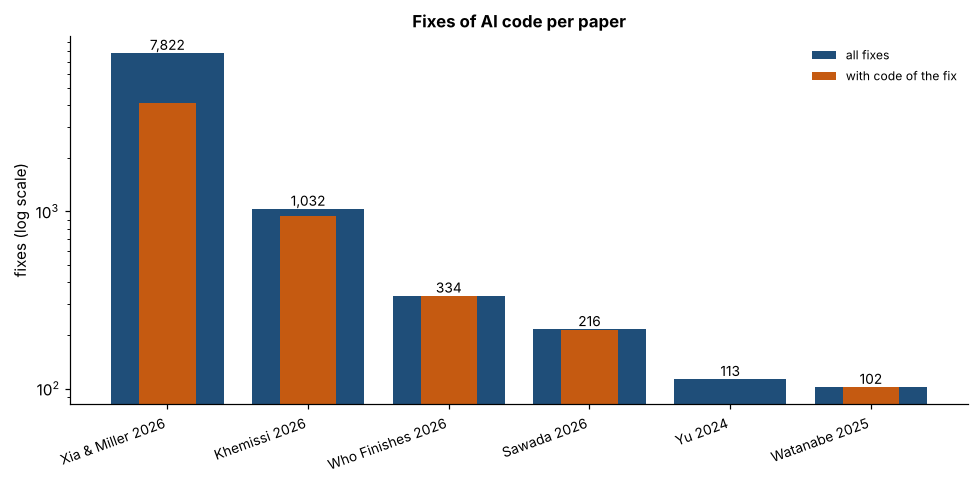

*Exact numbers – fixes per paper*

,fixes,with_code,python,how_labelled,%_of_all
paper,,,,,
Xia & Miller 2026,7822,4092,742,corrective (Swanson class),81.3
Khemissi 2026,1032,937,107,reference + fix keyword / manual label,10.7
Who Finishes 2026,334,334,35,Direct fix (LLM judge),3.5
Sawada 2026,216,214,40,fix (Conventional Commits),2.2
Yu 2024,113,0,53,fix commit (keyword),1.2
Watanabe 2025,102,102,38,fix (revision commit),1.1
TOTAL,9619,5679,1015,,100.0


In [9]:
c1 = final.groupby("paper").agg(fixes=("fix_id", "size"), with_code=("has_code_patch", "sum"),
        python=("is_python", "sum"), how_labelled=("fix_label", lambda s: s.str.replace(r"^reference: .*", "reference + fix keyword / manual label", regex=True).mode()[0]))
c1 = c1.sort_values("fixes", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(c1.index, c1["fixes"], color=BLUE, label="all fixes")
ax.bar(c1.index, c1["with_code"], color=ORANGE, width=0.4, label="with code of the fix")
for i, (v, w) in enumerate(zip(c1["fixes"], c1["with_code"])):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_yscale("log"); ax.set_ylabel("fixes (log scale)"); ax.set_title("Fixes of AI code per paper")
ax.legend(frameon=False, fontsize=8); plt.xticks(rotation=20, ha="right", fontsize=9)
save_chart(fig, "1_fixes_per_paper.png")
c1["%_of_all"] = (100 * c1["fixes"] / c1["fixes"].sum()).round(1)
c1.loc["TOTAL"] = [c1["fixes"].sum(), c1["with_code"].sum(), c1["python"].sum(), "", 100.0]
display(Markdown("*Exact numbers – fixes per paper*")); c1

### Chart 2 · Fixes per AI agent (all papers, coloured by paper)

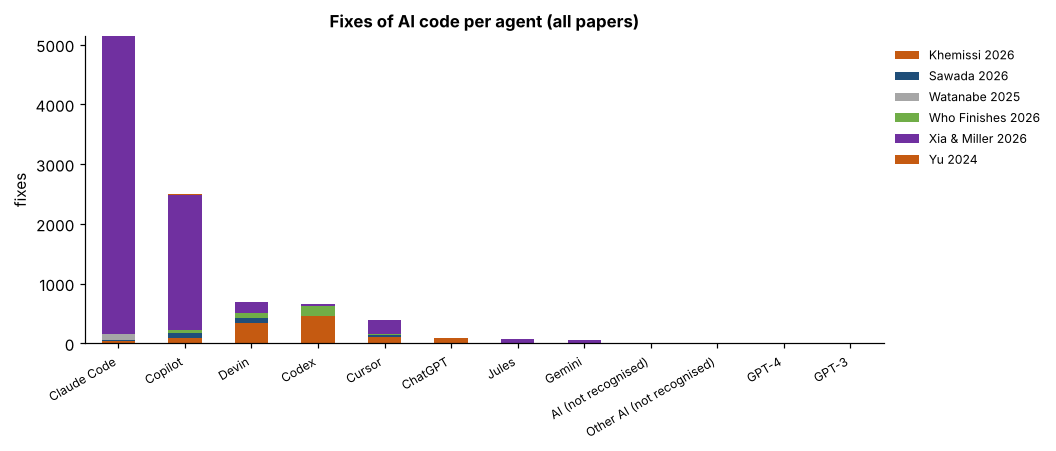

*Exact numbers – Fixes of AI code per agent (all papers)*

paper,Khemissi 2026,Sawada 2026,Watanabe 2025,Who Finishes 2026,Xia & Miller 2026,Yu 2024,TOTAL
agent,,,,,,,
GPT-3,0,0,0,0,0,3,3
GPT-4,0,0,0,0,0,6,6
Other AI (not recognised),0,10,0,0,0,0,10
AI (not recognised),0,0,0,0,12,0,12
Gemini,0,0,0,0,49,0,49
Jules,0,0,0,0,77,0,77
ChatGPT,0,0,0,0,0,85,85
Cursor,99,37,0,22,229,0,387
Codex,455,0,0,167,44,0,666


In [10]:
c2 = pd.crosstab(final["agent"], final["paper"])
c2 = c2.loc[:, c2.sum() > 0]
c2 = c2.loc[c2.sum(axis=1).sort_values().index]
stacked(c2, "Fixes of AI code per agent (all papers)", "2_fixes_per_agent.png", xlabel="fixes",
        colors=[ORANGE, BLUE, GREY, "#70AD47", "#7030A0"][: c2.shape[1]])

### Chart 3 · Who wrote the fix (human or AI agent), per paper

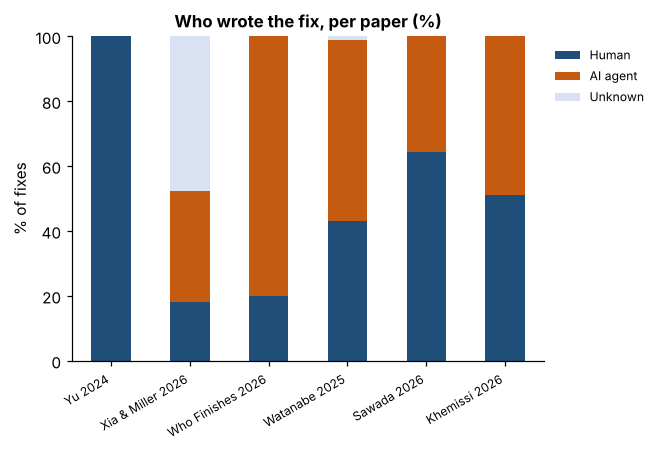

*Exact numbers – Who wrote the fix, per paper (%)*

fixed_by,Human,AI agent,Unknown,TOTAL
paper,,,,
Khemissi 2026,51.2,48.8,0.0,100.0
Sawada 2026,64.4,35.6,0.0,100.0
Watanabe 2025,43.1,55.9,1.0,100.0
Who Finishes 2026,20.1,79.9,0.0,100.0
Xia & Miller 2026,18.0,34.4,47.6,100.0
Yu 2024,100.0,0.0,0.0,100.0
TOTAL,296.8,254.6,48.6,600.0


In [11]:
c3 = pd.crosstab(final["paper"], final["fixed_by"], normalize="index").mul(100).round(1)
c3 = c3[[c for c in ["Human", "AI agent", "Unknown"] if c in c3]]
stacked(c3, "Who wrote the fix, per paper (%)", "3_who_fixes.png", colors=[BLUE, ORANGE, LIGHT], xlabel="% of fixes")

### Chart 4 · How fast the fix comes (papers with dates)

/tmp/ipykernel_439/184353641.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, tick_labels=[f"{p}\n(median {d.median():.0f} d)" for p, d in zip(papers_d, data)], vert=True, showfliers=False)


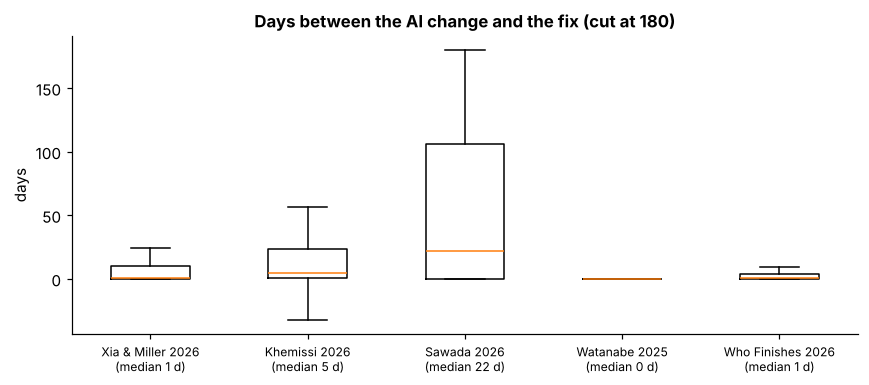

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
papers_d = [p for p in final.paper.unique() if final.loc[final.paper == p, "days_to_fix"].notna().any()]
data = [final.loc[final.paper == p, "days_to_fix"].dropna().clip(upper=180) for p in papers_d]
ax.boxplot(data, tick_labels=[f"{p}\n(median {d.median():.0f} d)" for p, d in zip(papers_d, data)], vert=True, showfliers=False)
ax.set_title("Days between the AI change and the fix (cut at 180)"); ax.set_ylabel("days"); plt.xticks(fontsize=8)
save_chart(fig, "4_days_to_fix.png")

### Extra · Python fixes per agent (our focus)

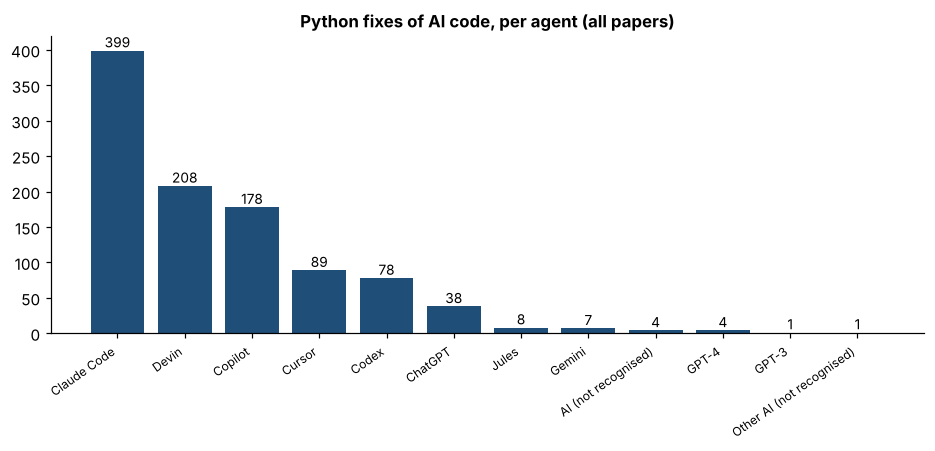

*Exact numbers – Python fixes of AI code, per agent (all papers)*

,number,%
agent,,
Claude Code,399.0,39.3
Devin,208.0,20.5
Copilot,178.0,17.5
Cursor,89.0,8.8
Codex,78.0,7.7
ChatGPT,38.0,3.7
Jules,8.0,0.8
Gemini,7.0,0.7
AI (not recognised),4.0,0.4


In [13]:
bar(python_fixes["agent"].value_counts(), "Python fixes of AI code, per agent (all papers)", "5_python_fixes_per_agent.png", horizontal=True)

### Final figure – all papers

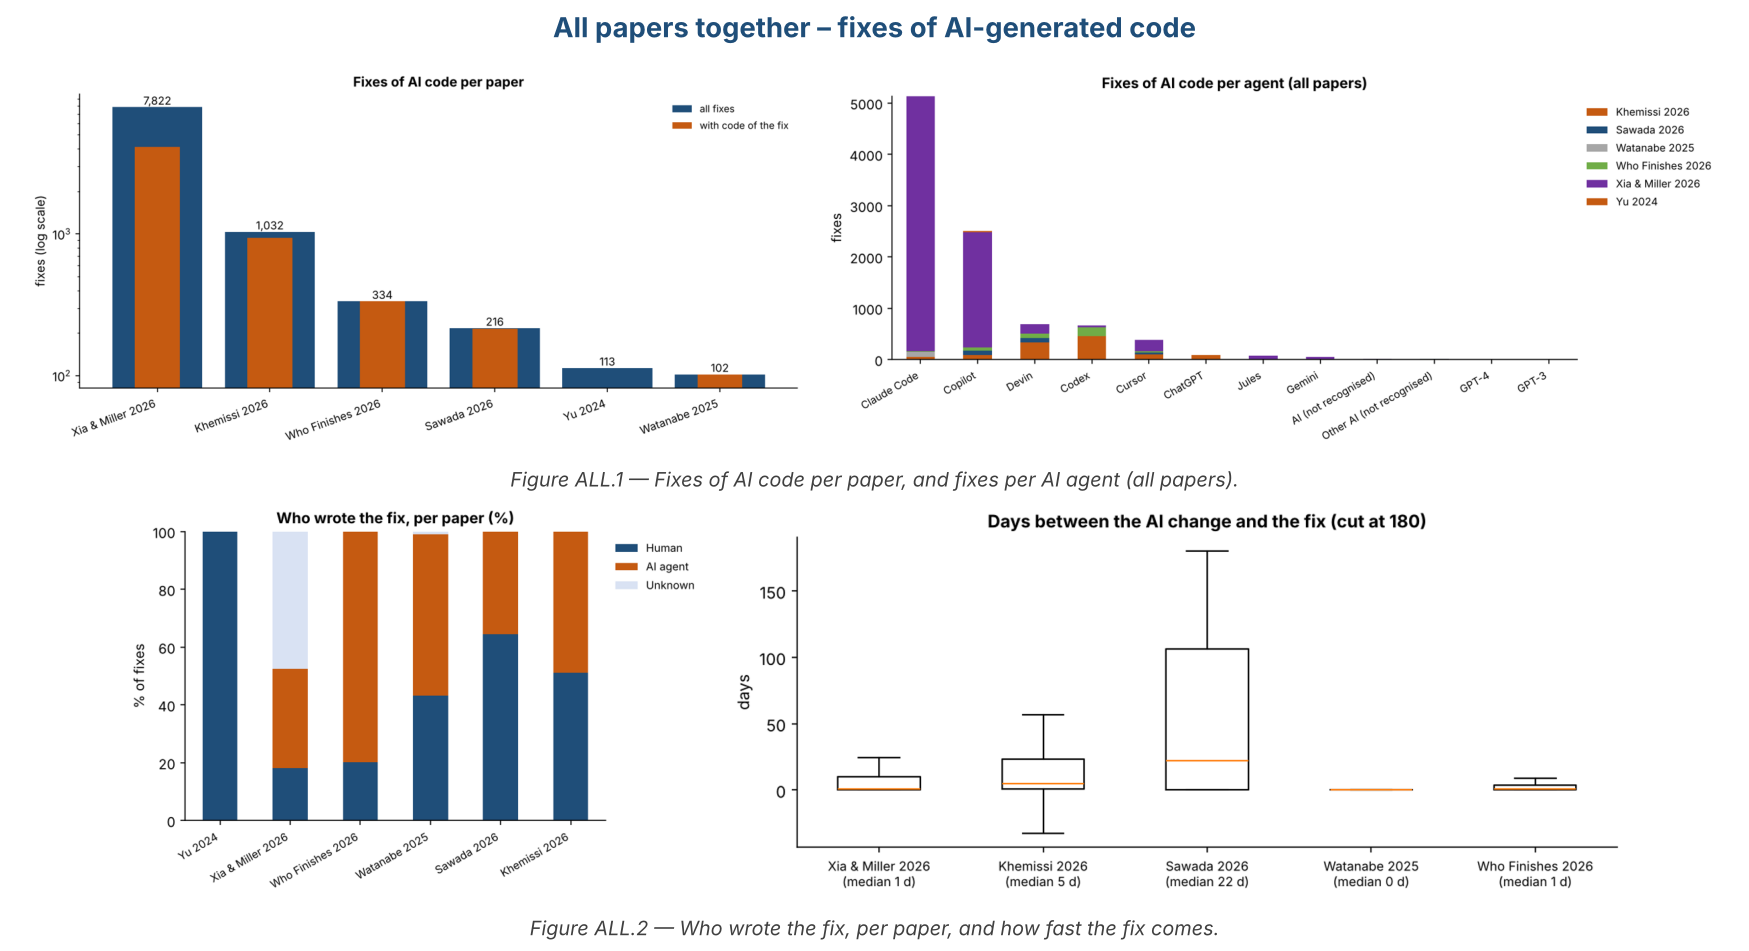

In [14]:
final_figure("ALL", "All papers together – fixes of AI-generated code",
             "Fixes of AI code per paper, and fixes per AI agent (all papers).",
             "Who wrote the fix, per paper, and how fast the fix comes.")

## 6. Save the FINAL DATASET

In [15]:
final.to_csv(os.path.join(OUT, "FINAL_AI_FIXES_DATASET.csv"), index=False)
with pd.ExcelWriter(os.path.join(OUT, "FINAL_AI_FIXES_DATASET.xlsx")) as xw:
    pd.DataFrame({"sheet": ["1 papers", "2 items per agent", "3 ALL FIXES", "4 by agent", "5 agent x paper", "6 who fixed", "7 by language", "8 python fixes"],
                  "content": ["one line per paper", "data per agent in each paper", "the final dataset (all fixes, grouped by agent -> paper)",
                              "fixes per agent", "fixes per agent and paper", "who wrote the fix, per paper", "fixes per language", "Python fixes only"]}
                 ).to_excel(xw, sheet_name="README", index=False)
    cards.to_excel(xw, sheet_name="1 papers", index=False)
    items.reset_index().to_excel(xw, sheet_name="2 items per agent", index=False)
    final.to_excel(xw, sheet_name="3 ALL FIXES", index=False)
    by_agent.reset_index().to_excel(xw, sheet_name="4 by agent", index=False)
    by_agent_paper.reset_index().to_excel(xw, sheet_name="5 agent x paper", index=False)
    by_paper_who.reset_index().to_excel(xw, sheet_name="6 who fixed", index=False)
    by_language.reset_index().to_excel(xw, sheet_name="7 by language", index=False)
    python_fixes.to_excel(xw, sheet_name="8 python fixes", index=False)
print(f"Saved data/FINAL_DATASET/FINAL_AI_FIXES_DATASET.xlsx / .csv  ({len(final):,} fixes)")

Saved data/FINAL_DATASET/FINAL_AI_FIXES_DATASET.xlsx / .csv  (9,619 fixes)
